In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (10, 5)})

In [2]:
project_root = Path.cwd().parent
path_to_data = project_root / 'data' / 'incoming' / 'history.csv' 

In [3]:
df = pd.read_csv(path_to_data)

df['review_dttm'] = pd.to_datetime(df['review_dttm'])
df['finish_dttm'] = pd.to_datetime(df['finish_dttm'])
df['id_client'] = df['id_client'].astype('string')
df['children_cnt'] = pd.to_numeric(df['children_cnt']).astype('Int64')
df['csat_score'] = pd.to_numeric(df['csat_score']).astype('float64')
df['review_text'] = df['review_text'].astype('string')

categorical_cols = [
    'company', 'review_mark', 'review_emotion', 'review_source',
    'business_line', 'product', 'reason', 'review_theme', 'subtheme',
    'solution_flg', 'gender_cd', 'education_level_cd', 'marital_status_cd',
    'citizenship_country', 'segment_name', 'subscription_important_flg',
    'new_flg', 'influencer_flg', 'age_segment',
]
df[categorical_cols] = df[categorical_cols].astype('category')

# Первичный обзор

In [4]:
df.shape # общее количество записей

(34124, 25)

In [5]:
df.head(5)

,review_dttm,finish_dttm,id_client,company,review_mark,review_emotion,review_source,business_line,product,reason,...,education_level_cd,marital_status_cd,children_cnt,citizenship_country,segment_name,subscription_important_flg,new_flg,influencer_flg,age_segment,csat_score
0,2025-01-01 00:00:01,2025-01-01 10:43:52,6c24df041eac4d91780531d351c438e8,Банк,5,Позитивный,banki.ru,премиальные сервисы,private,Не определено,...,NaN,NaN,0,РФ,Высокодоходные с ПМ,1.0,0.0,1.0,Взрослые,NaN
1,2025-01-01 00:39:35,2025-01-01 11:04:40,0f5af514772b946640d0d1b2d60cccac,Банк,5,Позитивный,banki.ru,депозитные продукты,накопительный счет,Не определено,...,NaN,NaN,0,РФ,Доходные,0.0,0.0,0.0,Подростки,NaN
2,2025-01-01 02:24:38,2025-01-01 10:53:41,d6f0d23891be4b02674695d1ab297a92,Банк,5,Позитивный,banki.ru,нефинансовые продукты,отели,Не определено,...,PGR,DIV,0,РФ,Доходные,0.0,0.0,0.0,Взрослые,NaN
3,2025-01-01 02:45:00,2025-01-08 09:11:51,e265bf6a1f7f0424222ba7238436ab87,Банк,1,Негативный,banki.ru,кредит наличными,кредит наличными,бюро кредитных историй,...,GRD,UNM,0,РФ,Доходные,0.0,0.0,0.0,Взрослые,NaN
4,2025-01-01 04:19:15,2025-01-01 10:51:01,e1a4f209b180acd8b1b59737e88cdd70,Банк,5,Позитивный,banki.ru,депозитные продукты,дебетовая карта,Не определено,...,GRD,MAR,0,РФ,Доходные,0.0,0.0,0.0,Сеньоры,NaN


# Обзор колонок

In [6]:
def classify_column(col):
    series = df[col]

    if pd.api.types.is_datetime64_any_dtype(series):
        return 'дата'

    if pd.api.types.is_numeric_dtype(series):
        return 'числовой'
    
    if pd.api.types.is_string_dtype(series):
            return 'строковый' if series.str.len().mean() > 30 else 'категориальный'
    
    numeric_values = pd.to_numeric(series, errors='coerce')
    non_missing = series.notna()

    if (
        non_missing.any()
        and numeric_values[non_missing].notna().all()
        and numeric_values.nunique(dropna=True) > 2
    ):
        return 'числовой'

    return 'категориальный'


columns_table = pd.DataFrame({
    'Поле': df.columns,
    'Тип данных': [classify_column(col) for col in df.columns],
})

display(columns_table)


,Поле,Тип данных
0,review_dttm,дата
1,finish_dttm,дата
2,id_client,строковый
3,company,категориальный
4,review_mark,категориальный
5,review_emotion,категориальный
6,review_source,категориальный
7,business_line,категориальный
8,product,категориальный
9,reason,категориальный


## Описательная статистика количественных переменных

In [7]:
quant_cols = columns_table.loc[
    columns_table['Тип данных'] == 'числовой', 'Поле'
].tolist()

quant_df = df[quant_cols].copy()


stats = pd.DataFrame({
    'Минимум': quant_df.min(),
    'Максимум': quant_df.max(),
    'Среднее': quant_df.mean(),
    'Медиана': quant_df.median(),
    'Мода': quant_df.apply(
        lambda col: col.mode().iloc[0] if not col.mode().empty else np.nan
    ),
    'Дисперсия': quant_df.var(),
    'Стандартное отклонение': quant_df.std(),
}).round(3)

display(stats)

,Минимум,Максимум,Среднее,Медиана,Мода,Дисперсия,Стандартное отклонение
children_cnt,0.0,6.0,0.079,0.0,0.0,0.138,0.372
csat_score,1.0,5.0,1.616,1.0,1.0,1.837,1.355


## Частотные таблицы для категориальных переменных

In [8]:
cat_cols = columns_table.loc[
    columns_table['Тип данных'] == 'категориальный', 'Поле'
].tolist()
cat_cols = [col for col in cat_cols if col != 'id_client']

markdown_tables = ['# Частотные таблицы категориальных признаков', '']

for col in cat_cols:
    counts = df[col].value_counts(dropna=False)
    freq_table = pd.DataFrame({
        'Количество': counts,
        'Доля, %': (counts / len(df) * 100).round(2),
    })
    top_values = freq_table.head(20)

    print(f'\n{col}')
    display(top_values)

    


company


,Количество,"Доля, %"
company,,
Банк,22930,67.20
Страховая,5248,15.38
SME,3004,8.80
Инвест,2336,6.85
Мобайл,560,1.64
ТРабота,46,0.13



review_mark


,Количество,"Доля, %"
review_mark,,
5,20624,60.44
без оценки (негативный),5831,17.09
1,5663,16.60
без оценки (нейтральный),692,2.03
2,601,1.76
4,350,1.03
3,263,0.77
без оценки (позитивный),100,0.29



review_emotion


...

,Количество,"Доля, %"
new_flg,,
0.0,26030,76.28
NaN,7443,21.81
1.0,651,1.91



influencer_flg


,Количество,"Доля, %"
influencer_flg,,
0.0,19946,58.45
NaN,7443,21.81
1.0,6735,19.74



age_segment


,Количество,"Доля, %"
age_segment,,
Взрослые,15263,44.73
NaN,5951,17.44
Молодежь,5763,16.89
Сеньоры,3586,10.51
Подростки,1991,5.83
Не определен,1557,4.56
Дети,13,0.04


# Качество данных

## Пропуски

In [9]:
missing_table = pd.DataFrame({
    'Количество пропусков': df.isna().sum(),
    'Доля пропусков, %': (df.isna().mean() * 100).round(2),
})

display(missing_table.sort_values('Количество пропусков', ascending=False))

,Количество пропусков,"Доля пропусков, %"
csat_score,31118,91.19
education_level_cd,18870,55.30
marital_status_cd,11289,33.08
children_cnt,8353,24.48
segment_name,7443,21.81
influencer_flg,7443,21.81
new_flg,7443,21.81
subscription_important_flg,7443,21.81
age_segment,5951,17.44
review_text,885,2.59


## Дубликаты

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['review_text'].str.strip().str.lower().duplicated().sum()

np.int64(1204)

In [12]:
normalized_text = df['review_text'].str.strip().str.lower()
text_counts = normalized_text.value_counts()

duplicates_table = (
    text_counts[text_counts > 1]
    .sub(1)
    .rename('Количество дубликатов')
    .rename_axis('Текст')
    .reset_index()
)

display(duplicates_table)

,Текст,Количество дубликатов
0,недавно (08.02.2025) обратилась в т-банк за по...,8
1,<p>здравствуйте!</p>\n<p>прошу помочь решить в...,4
2,проблемы с отображением транзакции сотрудник: ...,4
3,"оформили моментально, к документам не придирал...",2
4,"был вопрос о начислении кэшбек, по спец предло...",2
...,...,...
295,недавно открыл брокерский счет в т-банке. реши...,1
296,заболела нога в путешествии. \n\nсотрудники ст...,1
297,во-первых самый лучший банк . всегда дистанцио...,1
298,"немного растерян по поводу смены тарифа с ""инв...",1


In [13]:
df[df['review_text'].str.strip().str.lower().str.contains('выражаю благодарность команде т- банка и лично')] 

,review_dttm,finish_dttm,id_client,company,review_mark,review_emotion,review_source,business_line,product,reason,...,education_level_cd,marital_status_cd,children_cnt,citizenship_country,segment_name,subscription_important_flg,new_flg,influencer_flg,age_segment,csat_score


Имеются дубликаты в текстах отзыва. В качестве детализации был взят самый частый случа дубликации. Результат - у всех одинаковый клиент, но обращения формально разные (имеют разное время). Принято решение убрать дубликаты таких отзывов.

In [14]:
normalized_text = df['review_text'].astype('string').str.strip().str.casefold()
duplicate_mask = normalized_text.notna() & normalized_text.duplicated(keep='first')

removed_count = int(duplicate_mask.sum())
df = df.loc[~duplicate_mask].copy().reset_index(drop=True)

print(f'Удалено записей: {removed_count}')
print(f'Строк осталось: {len(df)}')

Удалено записей: 320
Строк осталось: 33804


## Выбросы и невозможные значения

Выбросов среди численных переменных нет (количество детей не имеет невозможных значений и это единственный целочисленный столбец).

# Целевые переменные

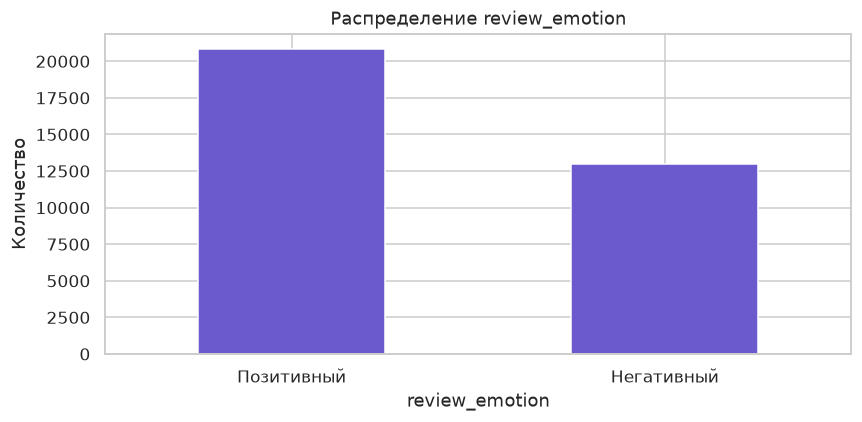

Распределение review_emotion, %:


,"Доля, %"
review_emotion,
Позитивный,61.63
Негативный,38.37


In [15]:
fig, ax = plt.subplots(figsize=(8, 4))

emotion_counts = df['review_emotion'].value_counts(dropna=False)
emotion_counts.plot(kind='bar', ax=ax, color='slateblue')
ax.set_title('Распределение review_emotion')
ax.set_ylabel('Количество')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print('Распределение review_emotion, %:')
display((emotion_counts / len(df) * 100).round(2).rename('Доля, %').to_frame())

## Связь с целевыми переменными

Для числовых и порядковых признаков была применена корреляция спирмена для выяснения связи между признаками

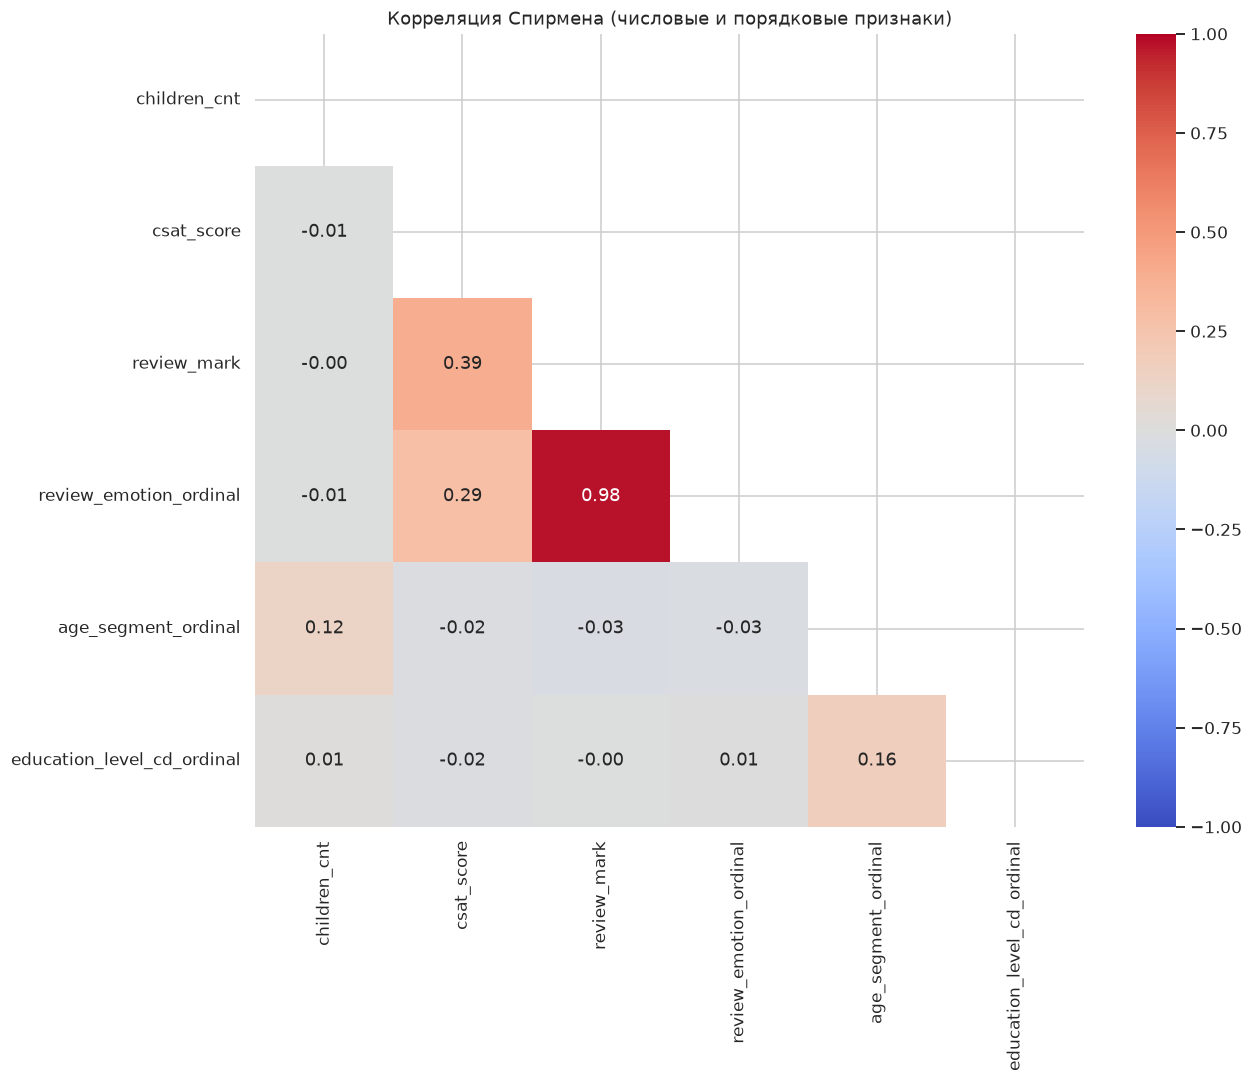

In [16]:


corr_data = pd.DataFrame(index=df.index)

# количественные признаки
quantitative_cols = ['children_cnt', 'csat_score']

# порядковые категориалы -> числовая шкала
ordinal_mappings = {
    'review_emotion': {'негативный': 1, 'нейтральный': 2, 'позитивный': 3},
    'age_segment': {'дети': 1, 'подростки': 2, 'молодежь': 3, 'взрослые': 4, 'сеньоры': 5},
    # порядок кодов задан по смыслу (уровень образования); таблица смыслов коды не расшифровывает
    'education_level_cd': {'sch': 1, 'ugr': 2, 'grd': 3, 'pgr': 4, 'acd': 5},
}

for col in quantitative_cols:
    if col in df.columns:
        corr_data[col] = pd.to_numeric(df[col], errors='coerce')

# review_mark — порядковая 1..5; строки «без оценки» дают NaN
corr_data['review_mark'] = pd.to_numeric(df['review_mark'], errors='coerce')

for col, mapping in ordinal_mappings.items():
    if col in df.columns:
        corr_data[f'{col}_ordinal'] = df[col].astype(str).str.lower().map(mapping)

corr_data = corr_data.loc[:, corr_data.nunique(dropna=True) > 1]
corr_data = corr_data.dropna(axis=1, how='all')

spearman_corr = corr_data.corr(method='spearman')

mask = np.triu(np.ones_like(spearman_corr, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(
    spearman_corr,
    mask=mask,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f'
)
plt.title('Корреляция Спирмена (числовые и порядковые признаки)')
plt.tight_layout()
plt.show()


review_emotion, review_mark имеют сильную корреляцию. Остальные признаки имеют либо минимальную корреляцию, либо умеренную.

Для вывления связи между категориальными и таргетом (тоже катеогриальным признаком) использовался коэффициент Крамера

,Признак,Коэффициент Крамера,χ²,p-value
0,subtheme,0.773,20417.8,0.00e+00
1,solution_flg,0.730,18037.4,0.00e+00
2,review_theme,0.641,13901.7,0.00e+00
3,product,0.513,8962.4,0.00e+00
4,business_line,0.512,8897.3,0.00e+00
5,reason,0.372,4850.7,0.00e+00
6,company,0.318,3427.4,0.00e+00
7,review_source,0.313,3335.2,0.00e+00
8,gender_cd,0.090,273.7,1.76e-61
9,segment_name,0.072,140.6,2.07e-29


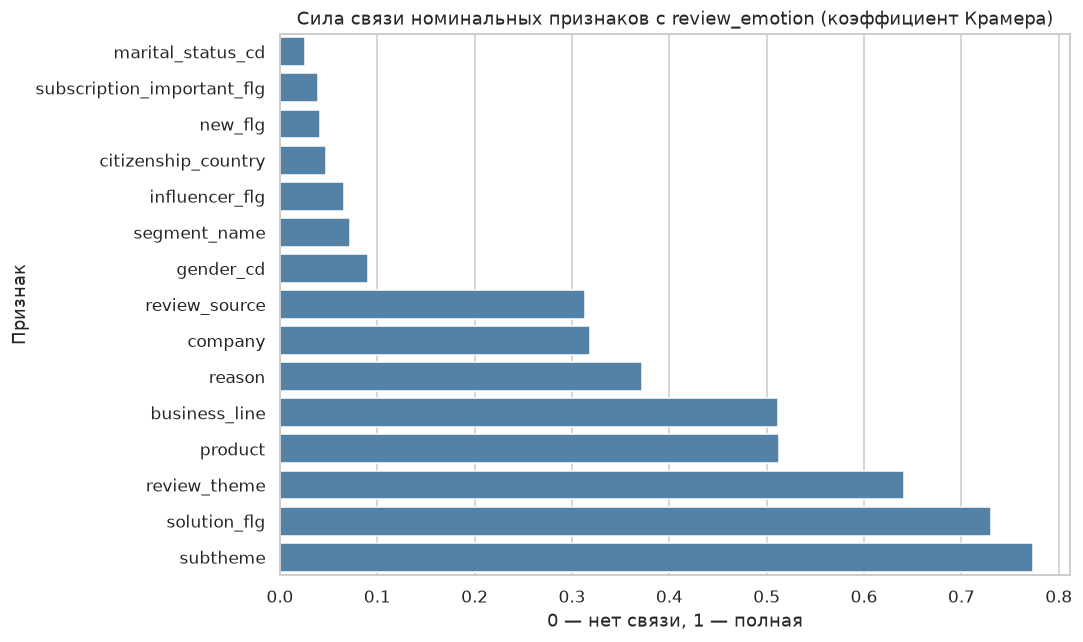

In [17]:

from scipy.stats import chi2_contingency


def cramers_v(x, y):
    ct = pd.crosstab(pd.Series(x).astype(str), pd.Series(y).astype(str))
    ct = ct.loc[ct.sum(axis=1) > 0, ct.sum(axis=0) > 0]
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    phi2 = chi2 / n
    r, k = ct.shape
    phi2corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rcorr = r - (r - 1) ** 2 / (n - 1)
    kcorr = k - (k - 1) ** 2 / (n - 1)
    denom = min(rcorr - 1, kcorr - 1)
    return np.sqrt(phi2corr / denom) if denom > 0 else np.nan


nominal_features = [
    'company', 'review_source', 'business_line', 'product', 'reason',
    'review_theme', 'subtheme', 'solution_flg', 'gender_cd',
    'marital_status_cd', 'citizenship_country',
    'segment_name', 'subscription_important_flg', 'new_flg',
    'influencer_flg',
]

rows = []
for col in nominal_features:
    if col not in df.columns:
        continue
    sub = df[[col, 'review_emotion']].dropna()
    ct = pd.crosstab(sub[col].astype(str), sub['review_emotion'].astype(str))
    ct = ct.loc[ct.sum(axis=1) > 0, ct.sum(axis=0) > 0]
    if ct.shape[0] < 2:
        continue
    chi2, p, dof, _ = chi2_contingency(ct)
    rows.append({
        'Признак': col,
        "Коэффициент Крамера": round(cramers_v(sub[col], sub['review_emotion']), 3),
        'χ²': round(chi2, 1),
        'p-value': f'{p:.2e}',
    })

target_link = (
    pd.DataFrame(rows)
    .sort_values("Коэффициент Крамера", ascending=False)
    .reset_index(drop=True)
)
display(target_link)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=target_link.sort_values("Коэффициент Крамера"),
    y='Признак', x="Коэффициент Крамера", color='steelblue',
)
plt.title("Сила связи номинальных признаков с review_emotion (коэффициент Крамера)")
plt.xlabel("0 — нет связи, 1 — полная")
plt.tight_layout()
plt.show()




По сути ни один признак, который используется в работе модели не имеет высокую корреляцию, из-за чего его можно записать в список признаков, который может вызвать утечку.

Для поиска взаимосвязи между категориальными признаками акже используется коэффициент Крамера

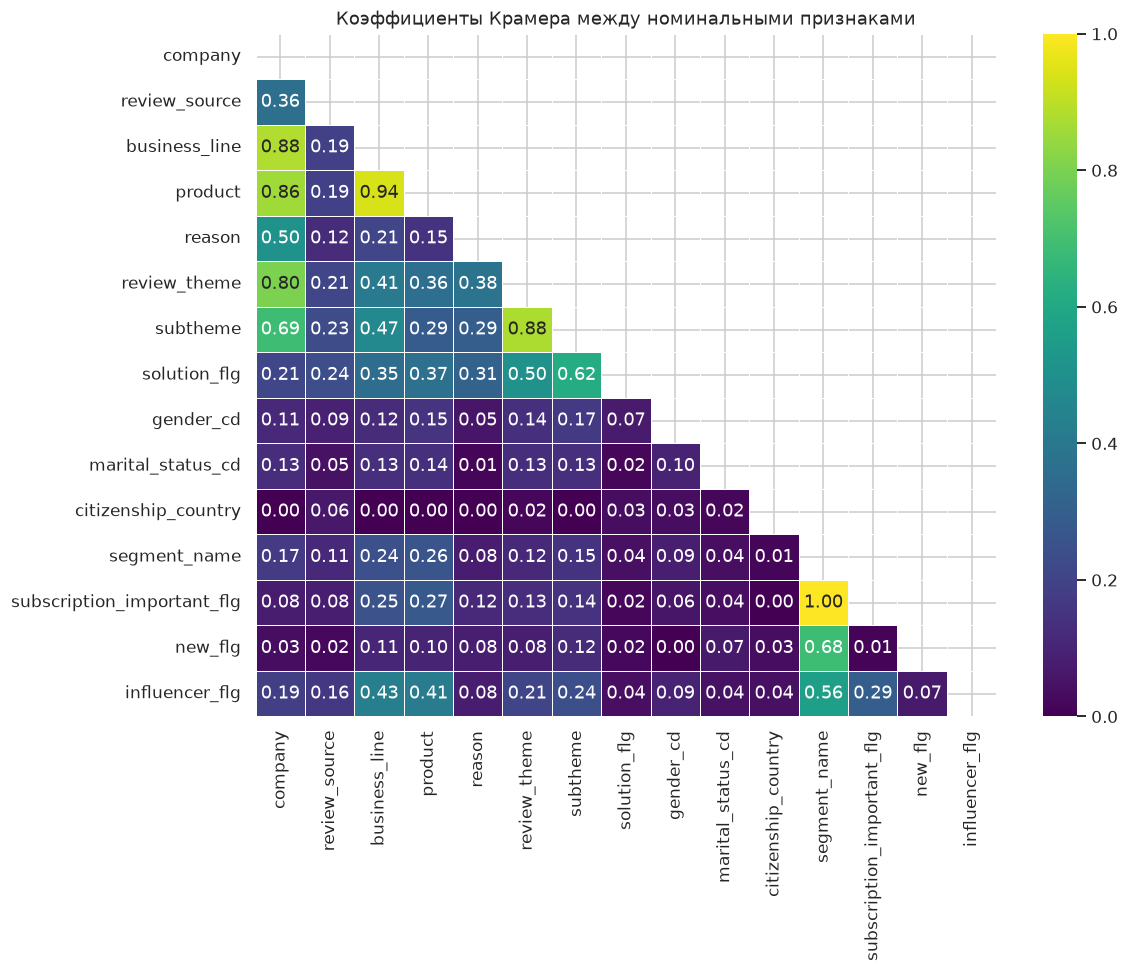

Кандидаты на дубликаты


,Признак 1,Признак 2,Cramér's V
0,segment_name,subscription_important_flg,0.999
1,business_line,product,0.939
2,company,business_line,0.880
3,review_theme,subtheme,0.875
4,company,product,0.858
5,company,review_theme,0.803
6,company,subtheme,0.689
7,segment_name,new_flg,0.684
8,subtheme,solution_flg,0.617


In [18]:

v_cols = [c for c in nominal_features if c in df.columns]

v_matrix = pd.DataFrame(np.nan, index=v_cols, columns=v_cols, dtype=float)
for a in v_cols:
    for b in v_cols:
        if a == b:
            v_matrix.loc[a, b] = 1.0
            continue
        sub = df[[a, b]].dropna()
        if sub[a].nunique() < 2 or sub[b].nunique() < 2:
            continue
        v_matrix.loc[a, b] = cramers_v(sub[a], sub[b])

mask = np.triu(np.ones(v_matrix.shape, dtype=bool))
plt.figure(figsize=(11, 9))
sns.heatmap(
    v_matrix, mask=mask, cmap='viridis', vmin=0, vmax=1,
    annot=True, fmt='.2f', linewidths=0.5,
)
plt.title("Коэффициенты Крамера между номинальными признаками")
plt.tight_layout()
plt.show()

pairs = []
for i, a in enumerate(v_cols):
    for b in v_cols[i + 1:]:
        val = v_matrix.loc[a, b]
        if pd.notna(val) and val >= 0.6:
            pairs.append((a, b, round(val, 3)))

strong_pairs = (
    pd.DataFrame(pairs, columns=['Признак 1', 'Признак 2', "Cramér's V"])
    .sort_values("Cramér's V", ascending=False)
    .reset_index(drop=True)
)
print("Кандидаты на дубликаты")
display(strong_pairs)


Из данной матрицы корреляции можно сделать вывод, что имеются вложенные уровни признаков: продукт вложен в бизнес линию, а бизнес линия в компанию. Сабтема в тему отзыва.

Предполагалось, что company и product могут пойти в модель, но из-за высокого коэффициента корреляции Крамера можно исключить company, поскольку он является дубликатом product.

Признаки, которые используюься в работе модели: product, review_source, review_text. Остальные признаки не будут известны в момент предсказания.

# Проверка гипотез

## Гипотеза 1. Негативные отзывы длиннее позитивных

Нулевая гипотеза: распределение длины текста отзыва одинаково для негативных и позитивных отзывов; различия в наблюдаемых длинах случайны.

Альтернативная гипотеза: тексты негативных отзывов в среднем длиннее текстов позитивных отзывов.

Сравниваются две независимые группы по количественному признаку (`text_len`), распределение которого сильно скошено вправо и не является нормальным, поэтому t-тест Стьюдента неприменим без дополнительных допущений. Самый простой устойчивый вариант — непараметрический критерий Манна–Уитни (ранговый аналог t-теста), он не требует нормальности. Для оценки практической значимости различия дополнительно считается размер эффекта (рангово-бисериальная корреляция): p-value показывает наличие различия, а размер эффекта — его величину.

,Всего,Медиана,Среднее
review_emotion,,,
Негативный,12970,615.0,762.72
Позитивный,20834,395.0,517.59


,Показатель,Значение
0,n негативных,12093
1,n позитивных,20826
2,U-статистика,158248406
3,p-value,0.00e+00
4,Размер эффекта (rank-biserial),0.257


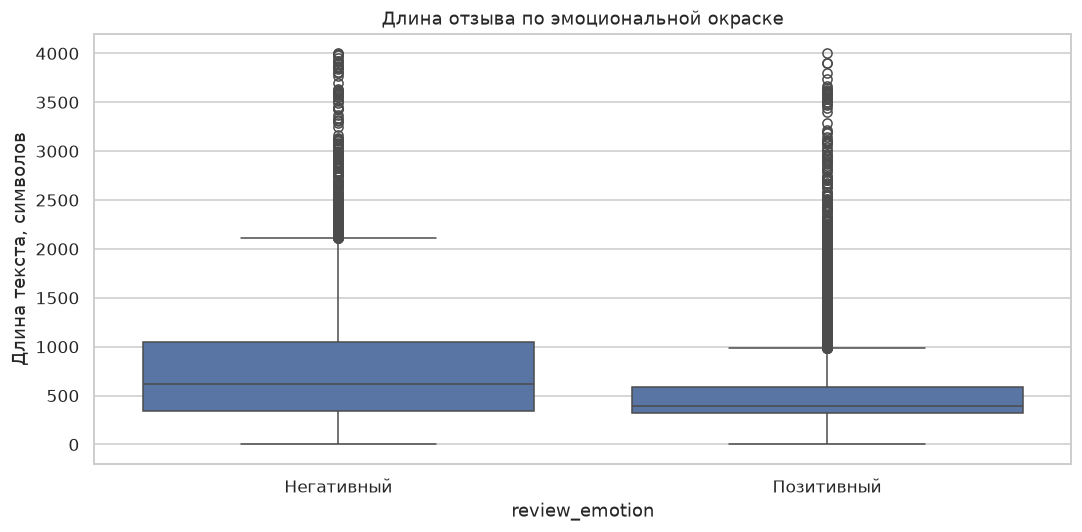

In [19]:
from scipy.stats import mannwhitneyu

df['text_len'] = df['review_text'].astype('string').str.len()

length_stats = (
    df.groupby('review_emotion', observed=True)['text_len']
    .agg(Всего='size', Медиана='median', Среднее='mean')
    .round(2)
)
display(length_stats)

negative_len = df.loc[df['review_emotion'] == 'Негативный', 'text_len'].dropna()
positive_len = df.loc[df['review_emotion'] == 'Позитивный', 'text_len'].dropna()

u_stat, p_value = mannwhitneyu(negative_len, positive_len, alternative='greater')

# размер эффекта: рангово-бисериальная корреляция
rank_biserial = 2 * u_stat / (len(negative_len) * len(positive_len)) - 1

display(pd.DataFrame({
    'Показатель': [
        'n негативных', 'n позитивных', 'U-статистика',
        'p-value', 'Размер эффекта (rank-biserial)',
    ],
    'Значение': [
        len(negative_len), len(positive_len), round(u_stat),
        f'{p_value:.2e}', round(rank_biserial, 3),
    ],
}))

sns.boxplot(data=df, x='review_emotion', y='text_len')
plt.title('Длина отзыва по эмоциональной окраске')
plt.xlabel('review_emotion')
plt.ylabel('Длина текста, символов')
plt.tight_layout()
plt.show()

Медианная длина негативного отзыва (615 симв.) примерно в 1.6 раза больше позитивного (395 симв.). Критерий Манна–Уитни даёт p ≈ 0 при U = 158 248 406, размер эффекта 0.257. Нулевая гипотеза отвергается: различие статистически значимо. Величина эффекта умеренная — длина сама по себе не разделяет классы идеально, но сигнал устойчив, поэтому признак `text_len` (и производные — число слов, средняя длина слова) обоснованно включается в план признаков.

## Гипотеза 2. Доля негатива систематически смещена по источнику

Нулевая гипотеза: эмоциональная окраска отзыва не зависит от источника; доли негатива по площадкам различаются только случайно.

Альтернативная гипотеза: распределение эмоциональной окраски различается между источниками — на одних площадках доля негатива систематически выше, чем на других.

Сравниваются два категориальных признака (`review_source` и `review_emotion`), поэтому простейший инструмент — таблица сопряжённости и критерий хи-квадрат Пирсона, который проверяет гипотезу независимости двух категориальных переменных. Для оценки силы связи дополнительно считается V Крамера — нормированная на объём выборки версия хи-квадрат в диапазоне от 0 до 1.

,Всего,Негативных,Доля негатива
review_source,,,
appstore,1,1,1.000
twitter,33,33,1.000
youtube,1,1,1.000
яндекс карты,7,7,1.000
форум banki.ru,1,1,1.000
одноклассники,17,17,1.000
гугл карты,2,2,1.000
пульс,718,716,0.997
вконтакте,236,235,0.996


Хи-квадрат = 3335.2, df = 18, p-value = 0.00e+00
Cramer's V = 0.313


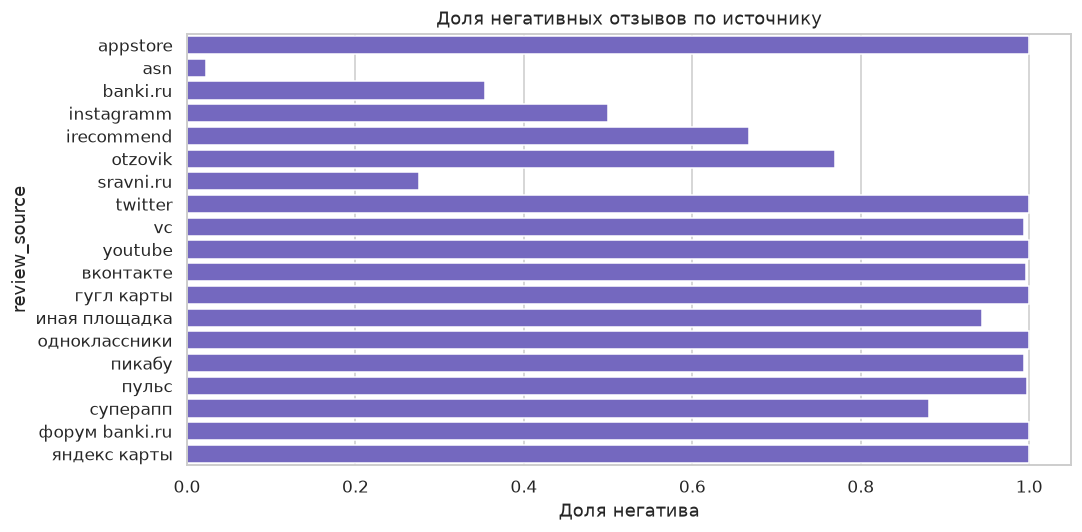

In [20]:
source_stats = (
    df.groupby('review_source', observed=True)['review_emotion']
    .agg(Всего='size', Негативных=lambda s: (s == 'Негативный').sum())
)
source_stats['Доля негатива'] = (source_stats['Негативных'] / source_stats['Всего']).round(3)
source_stats = source_stats.sort_values('Доля негатива', ascending=False)
display(source_stats)

sub = df[['review_source', 'review_emotion']].dropna()
ct = pd.crosstab(sub['review_source'], sub['review_emotion'])
chi2, p_value, dof, _ = chi2_contingency(ct)

print(f'Хи-квадрат = {chi2:.1f}, df = {dof}, p-value = {p_value:.2e}')
print(f"Cramer's V = {cramers_v(sub['review_source'], sub['review_emotion']):.3f}")

sns.barplot(
    data=source_stats.reset_index(),
    x='Доля негатива', y='review_source', color='slateblue',
)
plt.title('Доля негативных отзывов по источнику')
plt.xlabel('Доля негатива')
plt.ylabel('review_source')
plt.tight_layout()
plt.show()

Доля негатива резко различается по площадкам: от ~0.02 (asn) и 0.28 (sravni.ru) до 0.35 (banki.ru) и практически 1.0 (пульс, соцсети, otzovik). Критерий хи-квадрат даёт основание отклонить нулевую гипотезу, V Крамера = 0.313 — связь умеренная, но устойчивая. Вывод: `review_source` несёт информацию об окраске и обоснованно включается в признаки модели.

## Гипотеза 3. Негатив сильно различается от продукта к продукту
Нулевая гипотеза: эмоциональная окраска отзыва не зависит от продукта; доли негатива по продуктам различаются только случайно.
Альтернативная гипотеза: доля негативных отзывов систематически различается между продуктами (по кредитным продуктам негатива больше, чем по депозитным и страховым).

Как и в гипотезе 2, сравниваются два категориальных признака (`product` и `review_emotion`), поэтому используется тот же простейший инструмент — таблица сопряжённости, критерий хи-квадрат и V Крамера. Продукты с малым числом наблюдений (менее 30) отбрасываются, чтобы редкие категории не искажали статистику.

In [21]:
product_stats = (
    df.groupby('product', observed=True)['review_emotion']
    .agg(Всего='size', Негативных=lambda s: (s == 'Негативный').sum())
)
product_stats['Доля негатива'] = (product_stats['Негативных'] / product_stats['Всего']).round(3)

# оставляем продукты с достаточным объёмом наблюдений
product_stats = product_stats[product_stats['Всего'] >= 30]
product_stats = product_stats.sort_values('Доля негатива', ascending=False)
display(product_stats)

sub = df[df['product'].isin(product_stats.index)][['product', 'review_emotion']].dropna()
ct = pd.crosstab(sub['product'], sub['review_emotion'])
chi2, p_value, dof, _ = chi2_contingency(ct)

print(f'Хи-квадрат = {chi2:.1f}, df = {dof}, p-value = {p_value:.2e}')
print(f"Cramer's V = {cramers_v(sub['product'], sub['review_emotion']):.3f}")


,Всего,Негативных,Доля негатива
product,,,
collection,98,98,1.000
рефинансирование ипотеки,62,62,1.000
ипотека на вторичном рынке,44,43,0.977
мобайл,285,272,0.954
кредит наличными под залог недвижимости,123,117,0.951
кредит на покупку,154,141,0.916
кредит наличными,330,299,0.906
кубышка,43,37,0.860
кредит наличными под залог авто,39,33,0.846


Хи-квадрат = 8869.0, df = 40, p-value = 0.00e+00
Cramer's V = 0.513


Доля негатива упорядочена по типу продукта: кредитные продукты — 0.85–1.0 (кредит наличными 0.91, мобайл 0.95), тогда как депозитные и страховые — 0.06–0.14 (premium 0.06, осаго 0.14, взр 0.03). Критерий хи-квадрат отклоняет нулевую гипотезу, V Крамера = 0.513 — связь сильная. Вывод: `product` — наиболее информативный из доступных на инференсе категориальных признаков, включается в модель.

# Выводы

Прослеживается очевидная закономерность - определённе источники и категорий продуков имеют подавляющее число негативных отзывов (большинство) и наоборот. Причём, негативные отзывы в основном длинее положительных. Как таковых анамалий в данных не былло выявлено, кроме присутствия текстовых дубликатов отзывов от одних и тех же клиентов. Данных достаточно для дальнейшей работы и анализа.